# Column 坏点模式与可靠性质量控制

本 Notebook 只分析 `profiles_before_clean`，不删除、不插值、不覆盖原始 column profile。

分析顺序为：
1. 坏点所在的 cortical depth；
2. 每条 column 的坏点数量；
3. 坏点是否连续；
4. MD、FA、AD、RD 之间的坏点重合；
5. subject、半球和脑区分组。


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

QC_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/results/column_quality_qc')
DETAIL = QC_ROOT / 'column_badpoint_detail.csv'
FILE_SUMMARY = QC_ROOT / 'column_badpoint_file_summary.csv'
DEPTHS = 21
if not DETAIL.is_file() or not FILE_SUMMARY.is_file():
    raise FileNotFoundError('Run extract_column_badpoint_table.py first to generate the two CSV files.')
print('Reading cached results; raw profiles are not re-read.')
print('Detail:', DETAIL)
print('File summary:', FILE_SUMMARY)
detail = pd.read_csv(DETAIL, usecols=['subject','hemisphere','region','metric','column_id','bad_point_count','bad_depths','bad_types','has_consecutive_bad_points'])
file_summary = pd.read_csv(FILE_SUMMARY)
print('Loaded detail rows:', len(detail), 'file-summary rows:', len(file_summary))


## 1. 坏点所在的 cortical depth

统计每个 depth 的坏点数量和百分比，观察坏点是否集中在 depth 0、depth 20 或中间深度。

边界集中可能提示 mask、registration、surface sampling 或 partial-volume 问题，因此不能直接进行插值。


In [ ]:
depth_path = QC_ROOT / 'depth_pattern_summary.csv'
if depth_path.is_file():
    depth_table = pd.read_csv(depth_path)
    print('Using existing depth_pattern_summary.csv; depth is not recomputed.')
else:
    depth_rows=[]
    for row in detail.itertuples(index=False):
        if not row.bad_depths or pd.isna(row.bad_depths): continue
        for depth in str(row.bad_depths).split(';'):
            depth_rows.append({'metric':row.metric, 'depth':int(depth)})
    depth_table = pd.DataFrame(depth_rows).value_counts(['metric','depth']).rename('bad_points').reset_index()
    depth_table['total_points'] = FILE_SUMMARY.groupby('metric')['total_points'].sum().reindex(depth_table.metric).to_numpy()
    depth_table['bad_point_pct'] = 100 * depth_table.bad_points / depth_table.total_points
    depth_table.to_csv(depth_path, index=False)
display(depth_table.sort_values(['metric','depth']))


## 2. 每条 column 包含几个坏点

将每条 column 分为 0 个、1 个、2 个和 3 个及以上坏点。

如果大多数是单个坏点，局部插值可能可行；如果大量 column 有 3 个及以上坏点，应优先标记为低可靠性。


In [ ]:
detail['category'] = pd.cut(detail.bad_point_count, [-1,0,1,2,np.inf], labels=['0','1','2','3_or_more'])
category_table = detail.groupby(['metric','category'], observed=False).size().reset_index(name='column_count')
category_table.to_csv(QC_ROOT/'column_bad_count_summary.csv', index=False)
display(category_table)


## 3. 坏点是否连续

检查同一条 column 内是否存在相邻 depth 同时为坏点。连续坏点比单个孤立坏点更难通过线性插值可靠恢复。


In [ ]:
continuity_table = detail.groupby('metric', as_index=False).agg(
    columns_with_any_bad=('column_id','size'),
    columns_with_consecutive_bad=('has_consecutive_bad_points','sum'),
)
continuity_table['columns_all_depths_bad'] = detail.groupby('metric').bad_point_count.apply(lambda x: int((x >= DEPTHS).sum())).to_numpy()
continuity_table.to_csv(QC_ROOT/'column_continuity_summary.csv', index=False)
display(continuity_table)


## 4. 坏点是否跨 metric 重合

对相同 subject、半球、脑区、column 和 depth，检查 MD、FA、AD、RD 是否在同一位置同时异常。

只有一个 metric 异常，可能是局部 metric 数值问题；多个 metric 同时异常，则需要检查 mask、registration 或 surface sampling。


In [ ]:
# Using subject/hemi/region/column_id/depth from the detail table; raw metric CSVs are not re-read.
keys = ['subject','hemisphere','region','column_id']
expanded = detail.assign(depth=detail.bad_depths.fillna('').str.split(';')).explode('depth')
expanded = expanded[expanded.depth.ne('')].copy()
expanded['depth'] = expanded.depth.astype(int)
overlap = expanded.groupby(keys + ['depth']).metric.nunique().reset_index(name='bad_metric_count')
overlap_summary = overlap.groupby(keys, as_index=False).agg(
    total_bad_coordinates=('depth','size'),
    bad_in_2plus_metrics=('bad_metric_count', lambda x: int((x >= 2).sum())),
    bad_in_all_4_metrics=('bad_metric_count', lambda x: int((x == 4).sum())),
)
overlap_summary.to_csv(QC_ROOT/'cross_metric_overlap_summary.csv', index=False)
display(overlap_summary.head())


## 5. Subject、半球和脑区分组

汇总坏点比例、含坏点 column 比例和连续坏点 column 数，用于寻找集中异常的 subject、半球或脑区。


In [ ]:
file_summary = pd.read_csv(FILE_SUMMARY)
file_summary['bad_column_pct'] = 100 * file_summary.bad_columns / file_summary.total_columns.replace(0, np.nan)
group_summary = file_summary.groupby(['subject','hemisphere','region','metric'], as_index=False).agg(
    total_columns=('total_columns','sum'), bad_points=('bad_points','sum'), bad_columns=('bad_columns','sum'),
    empty_files=('status', lambda s: int((s == 'empty').sum())))
group_summary['bad_point_pct'] = 100 * group_summary.bad_points / (group_summary.total_columns * DEPTHS).replace(0, np.nan)
group_summary['bad_column_pct'] = 100 * group_summary.bad_columns / group_summary.total_columns.replace(0, np.nan)
group_summary.to_csv(QC_ROOT/'subject_hemisphere_region_badpoint_summary.csv', index=False)
display(group_summary.sort_values('bad_point_pct', ascending=False).head(20))


## 6. Retention and interpolation results

This section reads cached CSV results only. It does not re-read raw profiles.


In [ ]:
retention_path = QC_ROOT / 'subject_column_retention_curve.csv'
population_path = QC_ROOT / 'population_column_retention_summary.csv'
interp_path = QC_ROOT / 'interpolation_validation_summary.csv'
for required in (retention_path, population_path, interp_path):
    if not required.is_file():
        raise FileNotFoundError(f'Run column_retention_interpolation.py first: {required}')
retention = pd.read_csv(retention_path)
population_retention = pd.read_csv(population_path)
interpolation = pd.read_csv(interp_path)
print('Cached retention and interpolation results loaded.')
display(population_retention)
display(interpolation)


In [ ]:
plt.close('all')
allowed = list(range(6))
median = [population_retention.loc[population_retention.allowed_bad_points.eq(k), 'median_retention_pct'].iloc[0] for k in allowed if k in set(population_retention.allowed_bad_points)]
q1 = [population_retention.loc[population_retention.allowed_bad_points.eq(k), 'q1_retention_pct'].iloc[0] for k in allowed if k in set(population_retention.allowed_bad_points)]
q3 = [population_retention.loc[population_retention.allowed_bad_points.eq(k), 'q3_retention_pct'].iloc[0] for k in allowed if k in set(population_retention.allowed_bad_points)]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0,0].plot(allowed[:len(median)], median, marker='o', linewidth=2, label='Median')
axes[0,0].fill_between(allowed[:len(median)], q1, q3, alpha=.25, label='IQR')
axes[0,0].set(title='Population column retention curve', xlabel='Maximum allowed bad points', ylabel='Retention (%)', xticks=allowed)
axes[0,0].set_ylim(0, 100); axes[0,0].grid(alpha=.25); axes[0,0].legend()
for k in allowed:
    col = f'retention_allowed_{k}'
    if col in retention: axes[0,1].boxplot(retention[col].dropna(), positions=[k], widths=.55)
axes[0,1].set(title='Retention distribution across subjects', xlabel='Maximum allowed bad points', ylabel='Retention (%)', xticks=allowed)
axes[0,1].set_ylim(0,100); axes[0,1].grid(alpha=.25)
outliers = retention.nlargest(10, 'bad_point_pct')
for _, row in outliers.iterrows():
    available = [k for k in allowed if f'retention_allowed_{k}' in retention.columns]
    axes[1,0].plot(available, [row[f'retention_allowed_{k}'] for k in available], marker='o', label=row.subject)
axes[1,0].set(title='Highest bad-point subjects', xlabel='Maximum allowed bad points', ylabel='Retention (%)', xticks=allowed)
axes[1,0].set_ylim(0,100); axes[1,0].grid(alpha=.25); axes[1,0].legend(fontsize=8, ncol=2)
if {'metric','mae_mean'}.issubset(interpolation.columns):
    for metric, group in interpolation.groupby('metric'):
        axes[1,1].plot(group.artificial_bad_points, group.nmae_mean, marker='o', label=metric.upper())
    axes[1,1].set_ylabel('Normalized mean absolute error (NMAE)')
else:
    axes[1,1].bar(interpolation.artificial_bad_points.astype(str), interpolation.mae_mean)
    axes[1,1].set_ylabel('Mean absolute error (MAE)')
axes[1,1].set(title='Interpolation validation', xlabel='Artificially removed points'); axes[1,1].grid(alpha=.25); axes[1,1].legend()
fig.tight_layout(); out = QC_ROOT / 'retention_interpolation_overview.png'; fig.savefig(out, dpi=180, bbox_inches='tight'); display(fig)


## 7. Bad points per affected column

This shows how many bad depths occur within columns that contain at least one bad point.

In [ ]:
affected = detail.loc[detail.bad_point_count > 0, 'bad_point_count'].copy()
bins = pd.cut(affected, bins=[0,1,2,3,10,20,21], labels=['1','2','3','4-10','11-20','21'], include_lowest=False)
column_bad_distribution = bins.value_counts(sort=False).rename_axis('bad_depths_per_column').reset_index(name='column_count')
column_bad_distribution['percentage_of_affected_columns'] = 100 * column_bad_distribution.column_count / column_bad_distribution.column_count.sum()
total_columns_all = file_summary.loc[file_summary.status.eq('valid'), 'total_columns'].sum()
column_bad_distribution['percentage_of_all_columns'] = 100 * column_bad_distribution.column_count / total_columns_all
column_bad_distribution.to_csv(QC_ROOT / 'bad_depths_per_affected_column_summary.csv', index=False)
display(column_bad_distribution)
fig, ax = plt.subplots(figsize=(8,5)); ax.bar(column_bad_distribution.bad_depths_per_column.astype(str), column_bad_distribution.percentage_of_affected_columns)
ax.set(title='Bad depths per affected column', xlabel='Number of bad depths in a column', ylabel='Affected columns (%)'); ax.grid(axis='y', alpha=.25)
fig.tight_layout(); fig.savefig(QC_ROOT / 'bad_depths_per_affected_column.png', dpi=180); display(fig)


## 8. Region by depth heatmap

The heatmap uses the union of bad points across the four metrics and displays the cohort median percentage for each region and depth.

In [ ]:
file_meta = pd.read_csv(FILE_SUMMARY, usecols=['subject','hemisphere','region','metric','total_columns','status'])
valid_meta = file_meta[file_meta.status.eq('valid')]
denom = valid_meta.groupby(['subject','hemisphere','region'], as_index=False).total_columns.first()
expanded = detail.assign(depth=detail.bad_depths.fillna('').str.split(';')).explode('depth')
expanded = expanded[expanded.depth.ne('')].copy(); expanded['depth'] = expanded.depth.astype(int)
union = expanded.groupby(['subject','hemisphere','region','column_id','depth']).size().reset_index(name='metric_hits')
bad_counts = union.groupby(['subject','hemisphere','region','depth'], as_index=False).size().rename(columns={'size':'bad_count'})
heat = bad_counts.merge(denom, on=['subject','hemisphere','region'], how='left')
heat['bad_pct'] = 100 * heat.bad_count / heat.total_columns
heat = heat.groupby(['region','depth'], as_index=False).bad_pct.median()
pivot = heat.pivot(index='region', columns='depth', values='bad_pct').fillna(0)
pivot = pivot.loc[pivot.mean(axis=1).sort_values().index]
pivot.to_csv(QC_ROOT / 'region_depth_union_badpoint_heatmap.csv')
fig, ax = plt.subplots(figsize=(14, max(8, .23 * len(pivot))))
im = ax.imshow(pivot.to_numpy(), aspect='auto', cmap='magma', vmin=0, vmax=max(1, float(np.nanpercentile(pivot.to_numpy(), 99))))
ax.set(title='Cohort median bad-point percentage by region and depth', xlabel='Depth', ylabel='Region', xticks=range(len(pivot.columns)), xticklabels=pivot.columns, yticklabels=pivot.index)
fig.colorbar(im, ax=ax, label='Bad-point percentage (%)'); fig.tight_layout(); fig.savefig(QC_ROOT / 'region_depth_union_badpoint_heatmap.png', dpi=180); display(fig)


In [ ]:
top_subjects = retention.nlargest(5, 'bad_point_pct').subject.tolist()
subject_heatmap_dir = QC_ROOT / 'subject_heatmaps'
subject_heatmap_dir.mkdir(exist_ok=True)
for subject in top_subjects:
    sub_meta = valid_meta[valid_meta.subject.eq(subject)]
    sub_denom = sub_meta.groupby(['hemisphere','region'], as_index=False).total_columns.first()
    sub_expanded = expanded[expanded.subject.eq(subject)].copy()
    sub_bad = sub_expanded.groupby(['hemisphere','region','column_id','depth']).size().reset_index(name='metric_hits')
    sub_bad = sub_bad.groupby(['hemisphere','region','depth'], as_index=False).size().rename(columns={'size':'bad_count'})
    sub_heat = sub_bad.merge(sub_denom, on=['hemisphere','region'], how='left')
    sub_heat['bad_pct'] = 100 * sub_heat.bad_count / sub_heat.total_columns
    sub_heat = sub_heat.groupby(['region','depth'], as_index=False).bad_pct.max()
    sub_pivot = sub_heat.pivot(index='region', columns='depth', values='bad_pct').fillna(0)
    sub_pivot = sub_pivot.loc[sub_pivot.mean(axis=1).sort_values().index]
    sub_pivot.to_csv(subject_heatmap_dir / f'{subject}_region_depth_union_badpoint.csv')
    fig, ax = plt.subplots(figsize=(14, max(8, .23 * len(sub_pivot))))
    values = sub_pivot.to_numpy()
    im = ax.imshow(values, aspect='auto', cmap='magma', vmin=0, vmax=max(1, float(np.nanpercentile(values, 99))))
    ax.set(title=f'{subject}: bad-point percentage by region and depth', xlabel='Depth', ylabel='Region', xticks=range(len(sub_pivot.columns)), xticklabels=sub_pivot.columns, yticklabels=sub_pivot.index)
    fig.colorbar(im, ax=ax, label='Bad-point percentage (%)')
    fig.tight_layout(); fig.savefig(subject_heatmap_dir / f'{subject}_region_depth_union_badpoint.png', dpi=180); plt.close(fig)
print('Saved subject heatmaps:', top_subjects)


In [ ]:
top_subjects = retention.nlargest(5, 'bad_point_pct').subject.tolist()
subject_heatmap_dir = QC_ROOT / 'subject_heatmaps'
subject_heatmap_dir.mkdir(exist_ok=True)
for subject in top_subjects:
    sub_meta = valid_meta[valid_meta.subject.eq(subject)]
    sub_denom = sub_meta.groupby(['hemisphere','region'], as_index=False).total_columns.first()
    sub_expanded = expanded[expanded.subject.eq(subject)].copy()
    sub_bad = sub_expanded.groupby(['hemisphere','region','column_id','depth']).size().reset_index(name='metric_hits')
    sub_bad = sub_bad.groupby(['hemisphere','region','depth'], as_index=False).size().rename(columns={'size':'bad_count'})
    sub_heat = sub_bad.merge(sub_denom, on=['hemisphere','region'], how='left')
    sub_heat['bad_pct'] = 100 * sub_heat.bad_count / sub_heat.total_columns
    sub_heat = sub_heat.groupby(['region','depth'], as_index=False).bad_pct.max()
    sub_pivot = sub_heat.pivot(index='region', columns='depth', values='bad_pct').fillna(0)
    sub_pivot = sub_pivot.loc[sub_pivot.mean(axis=1).sort_values().index]
    sub_pivot.to_csv(subject_heatmap_dir / f'{subject}_region_depth_union_badpoint.csv')
    fig, ax = plt.subplots(figsize=(14, max(8, .23 * len(sub_pivot))))
    values = sub_pivot.to_numpy()
    im = ax.imshow(values, aspect='auto', cmap='magma', vmin=0, vmax=max(1, float(np.nanpercentile(values, 99))))
    ax.set_title(f'{subject}: bad-point percentage by region and depth')
    ax.set_xlabel('Depth'); ax.set_ylabel('Region')
    ax.set_xticks(range(len(sub_pivot.columns))); ax.set_xticklabels(sub_pivot.columns)
    ax.set_yticks(range(len(sub_pivot.index))); ax.set_yticklabels(sub_pivot.index)
    fig.colorbar(im, ax=ax, label='Bad-point percentage (%)')
    fig.tight_layout(); fig.savefig(subject_heatmap_dir / f'{subject}_region_depth_union_badpoint.png', dpi=180); plt.close(fig)
print('Saved subject heatmaps:', top_subjects)


## 9. Top five subject-specific heatmaps

The cohort heatmap above is a population median. This section creates one region-by-depth heatmap for each of the five subjects with the highest bad-point percentage.

In [ ]:
from IPython.display import display
top_subjects = retention.nlargest(5, 'bad_point_pct').subject.tolist()
subject_heatmap_dir = QC_ROOT / 'subject_heatmaps'
subject_heatmap_dir.mkdir(exist_ok=True)
for subject in top_subjects:
    sub_meta = valid_meta[valid_meta.subject.eq(subject)]
    sub_denom = sub_meta.groupby(['hemisphere','region'], as_index=False).total_columns.first()
    sub_expanded = expanded[expanded.subject.eq(subject)].copy()
    sub_bad = sub_expanded.groupby(['hemisphere','region','column_id','depth']).size().reset_index(name='metric_hits')
    sub_bad = sub_bad.groupby(['hemisphere','region','depth'], as_index=False).size().rename(columns={'size':'bad_count'})
    sub_heat = sub_bad.merge(sub_denom, on=['hemisphere','region'], how='left')
    sub_heat['bad_pct'] = 100 * sub_heat.bad_count / sub_heat.total_columns
    sub_heat = sub_heat.groupby(['region','depth'], as_index=False).bad_pct.max()
    sub_pivot = sub_heat.pivot(index='region', columns='depth', values='bad_pct').fillna(0)
    sub_pivot = sub_pivot.loc[sub_pivot.mean(axis=1).sort_values().index]
    sub_pivot.to_csv(subject_heatmap_dir / f'{subject}_region_depth_union_badpoint.csv')
    fig, ax = plt.subplots(figsize=(14, max(8, .23 * len(sub_pivot))))
    values = sub_pivot.to_numpy()
    im = ax.imshow(values, aspect='auto', cmap='magma', vmin=0, vmax=max(1, float(np.nanpercentile(values, 99))))
    ax.set_title(f'{subject}: bad-point percentage by region and depth')
    ax.set_xlabel('Depth'); ax.set_ylabel('Region')
    ax.set_xticks(range(len(sub_pivot.columns))); ax.set_xticklabels(sub_pivot.columns)
    ax.set_yticks(range(len(sub_pivot.index))); ax.set_yticklabels(sub_pivot.index)
    fig.colorbar(im, ax=ax, label='Bad-point percentage (%)')
    fig.tight_layout(); fig.savefig(subject_heatmap_dir / f'{subject}_region_depth_union_badpoint.png', dpi=180)
    display(fig); plt.close(fig)
print('Saved subject heatmaps:', top_subjects)


In [ ]:
excluded_subjects = retention.nlargest(5, 'bad_point_pct').subject.tolist()
comparison_root = QC_ROOT / 'excluding_top5'
comparison_root.mkdir(exist_ok=True)
retention_keep = retention[~retention.subject.isin(excluded_subjects)].copy()
detail_keep = detail[~detail.subject.isin(excluded_subjects)].copy()
file_keep = file_summary[~file_summary.subject.isin(excluded_subjects)].copy()

retention_summary = []
for label, frame in [('all_subjects', retention), ('excluding_top5', retention_keep)]:
    for k in range(6):
        col = f'retention_allowed_{k}'
        retention_summary.append({'cohort':label, 'allowed_bad_points':k,
            'median_retention_pct':frame[col].median(), 'q1_retention_pct':frame[col].quantile(.25),
            'q3_retention_pct':frame[col].quantile(.75), 'subjects':len(frame)})
pd.DataFrame(retention_summary).to_csv(comparison_root / 'retention_comparison_summary.csv', index=False)

affected_all = detail.bad_point_count[detail.bad_point_count > 0]
affected_keep = detail_keep.bad_point_count[detail_keep.bad_point_count > 0]
def distribution(series, label):
    categories = pd.cut(series, [0,1,2,3,10,20,21], labels=['1','2','3','4-10','11-20','21'])
    out = categories.value_counts(sort=False).rename_axis('bad_depths_per_column').reset_index(name='column_count')
    out['percentage_of_affected_columns'] = 100 * out.column_count / out.column_count.sum()
    out['cohort'] = label
    return out
dist_compare = pd.concat([distribution(affected_all, 'all_subjects'), distribution(affected_keep, 'excluding_top5')], ignore_index=True)
dist_compare.to_csv(comparison_root / 'bad_depth_distribution_comparison.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for label, frame in [('all_subjects', retention), ('excluding_top5', retention_keep)]:
    summary = retention_summary
    sub = pd.DataFrame(summary)
    sub = sub[sub.cohort.eq(label)].sort_values('allowed_bad_points')
    axes[0].plot(sub.allowed_bad_points, sub.median_retention_pct, marker='o', label=label)
    axes[0].fill_between(sub.allowed_bad_points, sub.q1_retention_pct, sub.q3_retention_pct, alpha=.15)
axes[0].set(title='Retention comparison', xlabel='Maximum allowed bad points', ylabel='Median retention (%)', xticks=range(6)); axes[0].set_ylim(0,100); axes[0].grid(alpha=.25); axes[0].legend()
for label, group in dist_compare.groupby('cohort'):
    axes[1].plot(group.bad_depths_per_column.astype(str), group.percentage_of_affected_columns, marker='o', label=label)
axes[1].set(title='Bad depths per affected column', xlabel='Bad depths in one column', ylabel='Affected columns (%)'); axes[1].grid(alpha=.25); axes[1].legend()
valid_all = file_summary[file_summary.status.eq('valid')]
valid_keep = file_keep[file_keep.status.eq('valid')]
for label, frame, det in [('all_subjects', valid_all, detail), ('excluding_top5', valid_keep, detail_keep)]:
    den = frame.groupby(['metric','subject'], as_index=False).total_columns.sum()
    ex = det.assign(depth=det.bad_depths.fillna('').str.split(';')).explode('depth'); ex = ex[ex.depth.ne('')].copy(); ex.depth = ex.depth.astype(int)
    bad = ex.groupby(['metric','subject','depth']).size().reset_index(name='bad_count')
    d = bad.groupby(['metric','depth'], as_index=False).bad_count.sum(); totals = den.groupby('metric').total_columns.sum()
    d['bad_pct'] = d.apply(lambda r: 100*r.bad_count/(totals[r.metric]), axis=1)
    for metric, g in d.groupby('metric'): axes[2].plot(g.depth, g.bad_pct, marker='o', label=f'{label}-{metric.upper()}')
axes[2].set(title='Depth-level bad-point percentage', xlabel='Depth', ylabel='Bad points (%)'); axes[2].grid(alpha=.25); axes[2].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(comparison_root / 'excluding_top5_comparison.png', dpi=180, bbox_inches='tight'); display(fig)
print('Excluded subjects:', excluded_subjects)
print('Comparison outputs:', comparison_root)


## 10. Exclusion sensitivity analysis

This compares the full cohort with the cohort after excluding the five subjects with the highest bad-point percentage. Original results are not overwritten.

In [ ]:
excluded_subjects = retention.nlargest(5, 'bad_point_pct').subject.tolist()
comparison_root = QC_ROOT / 'excluding_top5'
comparison_root.mkdir(exist_ok=True)
retention_keep = retention[~retention.subject.isin(excluded_subjects)].copy()
detail_keep = detail[~detail.subject.isin(excluded_subjects)].copy()
file_keep = file_summary[~file_summary.subject.isin(excluded_subjects)].copy()

retention_summary = []
for label, frame in [('all_subjects', retention), ('excluding_top5', retention_keep)]:
    available_k = [k for k in range(6) if f'retention_allowed_{k}' in retention.columns]
    for k in available_k:
        col = f'retention_allowed_{k}'
        retention_summary.append({'cohort':label, 'allowed_bad_points':k,
            'median_retention_pct':frame[col].median(), 'q1_retention_pct':frame[col].quantile(.25),
            'q3_retention_pct':frame[col].quantile(.75), 'subjects':len(frame)})
pd.DataFrame(retention_summary).to_csv(comparison_root / 'retention_comparison_summary.csv', index=False)

affected_all = detail.bad_point_count[detail.bad_point_count > 0]
affected_keep = detail_keep.bad_point_count[detail_keep.bad_point_count > 0]
def distribution(series, label):
    categories = pd.cut(series, [0,1,2,3,10,20,21], labels=['1','2','3','4-10','11-20','21'])
    out = categories.value_counts(sort=False).rename_axis('bad_depths_per_column').reset_index(name='column_count')
    out['percentage_of_affected_columns'] = 100 * out.column_count / out.column_count.sum()
    out['cohort'] = label
    return out
dist_compare = pd.concat([distribution(affected_all, 'all_subjects'), distribution(affected_keep, 'excluding_top5')], ignore_index=True)
dist_compare.to_csv(comparison_root / 'bad_depth_distribution_comparison.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for label, frame in [('all_subjects', retention), ('excluding_top5', retention_keep)]:
    summary = retention_summary
    sub = pd.DataFrame(summary)
    sub = sub[sub.cohort.eq(label)].sort_values('allowed_bad_points')
    axes[0].plot(sub.allowed_bad_points, sub.median_retention_pct, marker='o', label=label)
    axes[0].fill_between(sub.allowed_bad_points, sub.q1_retention_pct, sub.q3_retention_pct, alpha=.15)
axes[0].set(title='Retention comparison', xlabel='Maximum allowed bad points', ylabel='Median retention (%)', xticks=range(6)); axes[0].set_ylim(0,100); axes[0].grid(alpha=.25); axes[0].legend()
for label, group in dist_compare.groupby('cohort'):
    axes[1].plot(group.bad_depths_per_column.astype(str), group.percentage_of_affected_columns, marker='o', label=label)
axes[1].set(title='Bad depths per affected column', xlabel='Bad depths in one column', ylabel='Affected columns (%)'); axes[1].grid(alpha=.25); axes[1].legend()
valid_all = file_summary[file_summary.status.eq('valid')]
valid_keep = file_keep[file_keep.status.eq('valid')]
for label, frame, det in [('all_subjects', valid_all, detail), ('excluding_top5', valid_keep, detail_keep)]:
    den = frame.groupby(['metric','subject'], as_index=False).total_columns.sum()
    ex = det.assign(depth=det.bad_depths.fillna('').str.split(';')).explode('depth'); ex = ex[ex.depth.ne('')].copy(); ex.depth = ex.depth.astype(int)
    bad = ex.groupby(['metric','subject','depth']).size().reset_index(name='bad_count')
    d = bad.groupby(['metric','depth'], as_index=False).bad_count.sum(); totals = den.groupby('metric').total_columns.sum()
    d['bad_pct'] = d.apply(lambda r: 100*r.bad_count/(totals[r.metric]), axis=1)
    for metric, g in d.groupby('metric'): axes[2].plot(g.depth, g.bad_pct, marker='o', label=f'{label}-{metric.upper()}')
axes[2].set(title='Depth-level bad-point percentage', xlabel='Depth', ylabel='Bad points (%)'); axes[2].grid(alpha=.25); axes[2].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(comparison_root / 'excluding_top5_comparison.png', dpi=180, bbox_inches='tight'); display(fig)
print('Excluded subjects:', excluded_subjects)
print('Comparison outputs:', comparison_root)


## 11. Cohort heatmap excluding top five subjects

This heatmap shows the cohort median region-by-depth bad-point percentage after excluding the five highest-bad-point subjects.

In [ ]:
exclude_heatmap_dir = QC_ROOT / 'excluding_top5'
exclude_heatmap_dir.mkdir(exist_ok=True)
meta_keep = file_summary[(file_summary.status.eq('valid')) & (~file_summary.subject.isin(excluded_subjects))]
denom_keep = meta_keep.groupby(['subject','hemisphere','region'], as_index=False).total_columns.first()
expanded_keep = detail_keep.assign(depth=detail_keep.bad_depths.fillna('').str.split(';')).explode('depth')
expanded_keep = expanded_keep[expanded_keep.depth.ne('')].copy(); expanded_keep['depth'] = expanded_keep.depth.astype(int)
union_keep = expanded_keep.groupby(['subject','hemisphere','region','column_id','depth']).size().reset_index(name='metric_hits')
bad_keep = union_keep.groupby(['subject','hemisphere','region','depth']).size().reset_index(name='bad_count')
heat_keep = bad_keep.merge(denom_keep, on=['subject','hemisphere','region'], how='left')
heat_keep['bad_pct'] = 100 * heat_keep.bad_count / heat_keep.total_columns
heat_keep = heat_keep.groupby(['region','depth'], as_index=False).bad_pct.median()
pivot_keep = heat_keep.pivot(index='region', columns='depth', values='bad_pct').fillna(0)
pivot_keep = pivot_keep.loc[pivot_keep.mean(axis=1).sort_values().index]
pivot_keep.to_csv(exclude_heatmap_dir / 'region_depth_union_badpoint_heatmap.csv')
fig, ax = plt.subplots(figsize=(14, max(8, .23 * len(pivot_keep))))
values = pivot_keep.to_numpy()
im = ax.imshow(values, aspect='auto', cmap='magma', vmin=0, vmax=max(1, float(np.nanpercentile(values, 99))))
ax.set_title('Cohort median bad-point percentage excluding top five subjects')
ax.set_xlabel('Depth'); ax.set_ylabel('Region')
ax.set_xticks(range(len(pivot_keep.columns))); ax.set_xticklabels(pivot_keep.columns)
ax.set_yticks(range(len(pivot_keep.index))); ax.set_yticklabels(pivot_keep.index)
fig.colorbar(im, ax=ax, label='Bad-point percentage (%)')
fig.tight_layout(); fig.savefig(exclude_heatmap_dir / 'region_depth_union_badpoint_heatmap.png', dpi=180, bbox_inches='tight'); display(fig); plt.close(fig)
print('Saved:', exclude_heatmap_dir / 'region_depth_union_badpoint_heatmap.png')


## 12. Affected column summary

A column is affected if it contains at least one bad depth. This table reports affected columns as a percentage of all valid columns.

,cohort,total_columns,unaffected_columns,affected_columns,affected_column_pct
0,all_subjects,182520573,181591806,928767,0.508856
1,excluding_top5,177352333,176865098,487235,0.274727


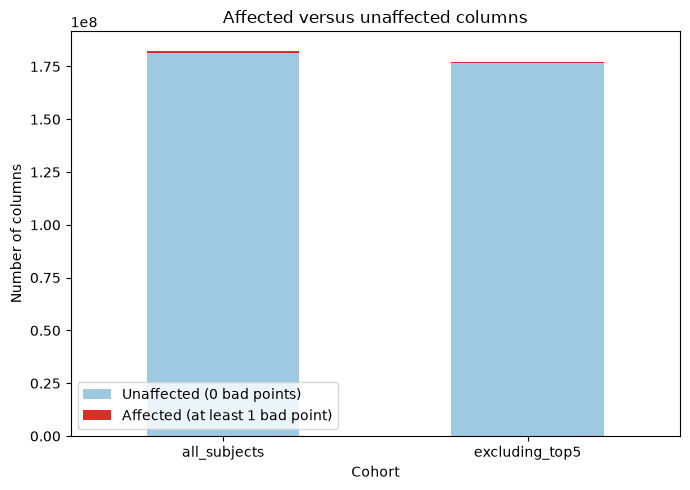

In [93]:
affected_rows = []
for label, frame in [('all_subjects', retention), ('excluding_top5', retention_keep)]:
    total = int(frame.total_columns.sum())
    affected = int(frame.bad_columns.sum())
    affected_rows.append({'cohort': label, 'total_columns': total,
                          'unaffected_columns': total - affected,
                          'affected_columns': affected,
                          'affected_column_pct': 100 * affected / total})
affected_summary = pd.DataFrame(affected_rows)
affected_summary.to_csv(QC_ROOT / 'affected_column_summary.csv', index=False)
display(affected_summary)
fig, ax = plt.subplots(figsize=(7,5))
plot = affected_summary.set_index('cohort')[['unaffected_columns','affected_columns']]
plot.plot(kind='bar', stacked=True, ax=ax, color=['#9ecae1','#de2d26'])
ax.set_title('Affected versus unaffected columns')
ax.set_xlabel('Cohort'); ax.set_ylabel('Number of columns'); ax.legend(['Unaffected (0 bad points)', 'Affected (at least 1 bad point)'])
ax.tick_params(axis='x', rotation=0); fig.tight_layout()
fig.savefig(QC_ROOT / 'affected_column_summary.png', dpi=180, bbox_inches='tight'); display(fig); plt.close(fig)


## 13. Union bad-column summary

A trajectory column is affected if any of MD, FA, AD, or RD contains at least one bad depth. Each trajectory column is counted only once across metrics.

In [94]:
union_keys = ['subject', 'hemisphere', 'region', 'column_id']
union_bad = detail[detail.bad_point_count > 0][union_keys].drop_duplicates()
valid_files = file_summary[file_summary.status.eq('valid')]
denom = valid_files.groupby(['subject','hemisphere','region'], as_index=False).total_columns.first()
affected_counts = union_bad.groupby(['subject','hemisphere','region'], as_index=False).size().rename(columns={'size':'affected_columns'})
denom = denom.merge(affected_counts, on=['subject','hemisphere','region'], how='left')
denom['affected_columns'] = denom.affected_columns.fillna(0).astype(int)
denom['unaffected_columns'] = denom.total_columns - denom.affected_columns
denom['affected_column_pct'] = 100 * denom.affected_columns / denom.total_columns.replace(0, np.nan)
denom.to_csv(QC_ROOT / 'union_bad_column_by_subject_region.csv', index=False)
subject_union = denom.groupby('subject', as_index=False).agg(total_columns=('total_columns','sum'), affected_columns=('affected_columns','sum'), unaffected_columns=('unaffected_columns','sum'))
subject_union['affected_column_pct'] = 100 * subject_union.affected_columns / subject_union.total_columns.replace(0, np.nan)
subject_union.to_csv(QC_ROOT / 'subject_union_bad_column_summary.csv', index=False)
cohort_union = pd.DataFrame([{'cohort':'all_subjects', 'total_columns':int(subject_union.total_columns.sum()), 'affected_columns':int(subject_union.affected_columns.sum()), 'unaffected_columns':int(subject_union.unaffected_columns.sum())}])
cohort_union['affected_column_pct'] = 100 * cohort_union.affected_columns / cohort_union.total_columns
cohort_union.to_csv(QC_ROOT / 'cohort_union_bad_column_summary.csv', index=False)
display(cohort_union); display(subject_union.nlargest(10, 'affected_column_pct'))


,cohort,total_columns,affected_columns,unaffected_columns,affected_column_pct
0,all_subjects,45826818,233006,45593812,0.508449


,subject,total_columns,affected_columns,unaffected_columns,affected_column_pct
132,D0222,276955,43610,233345,15.746240
39,D0094,233104,26178,206926,11.230181
183,D0279,263378,16401,246977,6.227172
20,D0072,236124,12311,223813,5.213786
150,D0242,282499,11883,270616,4.206387
21,D0073,266692,4790,261902,1.796079
57,D0114,266667,4620,262047,1.732498
162,D0255,251770,4047,247723,1.607419
177,D0273,254052,3550,250502,1.397352
53,D0110,259167,3309,255858,1.276783


In [95]:
metric_overlap = (
    detail[detail.bad_point_count > 0]
    .groupby(['subject', 'hemisphere', 'region', 'column_id'])
    ['metric']
    .nunique()
    .value_counts()
    .sort_index()
    .rename_axis('metric_count')
    .reset_index(name='column_count')
)

metric_overlap['percentage'] = (
    100 * metric_overlap['column_count']
    / metric_overlap['column_count'].sum()
)

metric_overlap.to_csv(
    QC_ROOT / 'union_bad_column_metric_overlap.csv',
    index=False
)

display(metric_overlap)

,metric_count,column_count,percentage
0,1,387,0.166090
1,2,1037,0.445053
2,3,22,0.009442
3,4,231560,99.379415
